# MAREA at the Ría de Villaviciosa

From Sentinel-2 looks to intertidal elevation, its uncertainty, the tide's delay and emersion time, on real data. The notebook first runs MAREA's elevation step on the sample block in `data/`, then reproduces the whole published product of the ría (`products_marea/`) from the replication kit in `replication/` and checks it.

1. **The looks.** Each scene, pixel by pixel: wet, dry or not clear.
2. **One pixel.** Its looks against the tide at the mouth and against its own, delayed tide.
3. **The block.** Every pixel of the sample, inverted again: the product's elevations, exactly.
4. **The ría.** Sections, delays and elevations from the kit, checked against the product.
5. **The maps.** Elevation, uncertainty, delay and emersion time.

No account, no download and no tide model are needed. It runs in one to two minutes. Heights are metres on the scale of the EOT20 tide model (about mean sea level); times are UTC.

In [1]:
# ── Setup: run from the repository root, whichever folder the notebook was opened in ──
import hashlib                                      # sha256 of the inputs
import json                                         # the kit's manifest
import os                                           # the working directory
import platform                                     # the Python version
import sys                                          # where the library and the helpers are imported from
import tempfile                                     # the reproduction's own output folder (section 4)
import time                                         # how long the reproduction takes
import warnings                                     # the outputs show results, not the packages' warnings
from pathlib import Path

warnings.filterwarnings('ignore')
ROOT = Path.cwd() if (Path.cwd() / 'pyintertidal').is_dir() else Path.cwd().parent
os.chdir(ROOT)                                      # every path below is relative to the repository root
for p in (str(ROOT), str(ROOT / 'scripts')):        # the library, and the kit's helpers in scripts/
    if p not in sys.path:
        sys.path.insert(0, p)

import matplotlib                                   # figures
import matplotlib.pyplot as plt
import netCDF4                                      # the sample's format (read through xarray)
import numpy as np
import pandas as pd
import scipy
import xarray as xr
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
from scipy.special import erf                       # the normal curve of MAREA's wet/dry step

import pyintertidal as pit                          # the MAREA library of this repository
from pyintertidal import marea                      # the looks, the inversion and the whole product
import marea_tools as mt                            # the replication kit's helpers (scripts/marea_tools.py)


def sha256(path):
    # sha256 of a file, read in 1 MB blocks
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()


# ── Provenance: the branch, the versions, and every input checked by its sha256 ──
manifest = json.loads(Path('replication/MANIFEST.json').read_text(encoding='utf-8'))
sums = dict(line.split()[::-1] for line in open('data/SHA256SUMS.txt', encoding='utf-8') if line.strip())
INPUTS = {'data/villaviciosa_sample.nc': sums['villaviciosa_sample.nc']}
INPUTS.update({f'replication/{k}': v['sha256'] for k, v in manifest['files'].items()})
INPUTS.update({f'products_marea/{k}': v for k, v in manifest['inputs']['product'].items()})
print('branch CARTOGRASS26 · notebooks/01_marea_villaviciosa.ipynb')
print(f'Python {platform.python_version()} · pyintertidal {pit.__version__} · numpy {np.__version__} · '
      f'scipy {scipy.__version__} · pandas {pd.__version__} · xarray {xr.__version__} · '
      f'netCDF4 {netCDF4.__version__} · matplotlib {matplotlib.__version__}')
for path, want in INPUTS.items():
    assert sha256(path) == want, path                # the very files the product was made and checked with
    print(f'  {path:52s} sha256 {want[:16]}  ok')

branch CARTOGRASS26 · notebooks/01_marea_villaviciosa.ipynb
Python 3.13.3 · pyintertidal 0.1.0 · numpy 2.4.6 · scipy 1.17.1 · pandas 2.3.3 · xarray 2025.1.1 · netCDF4 1.7.4 · matplotlib 3.10.9
  data/villaviciosa_sample.nc                          sha256 f5af038980e133cb  ok
  replication/villaviciosa_record_2023-2025.npz        sha256 21e222759d6ea5f3  ok
  replication/villaviciosa_eot20_levels.npz            sha256 6d6f675c35ae1b41  ok
  replication/villaviciosa_eot20_10min_2023-2025.npz   sha256 d80ad559a9b373f5  ok
  products_marea/result.json                           sha256 a1620b89cd51c0f4  ok
  products_marea/marea.npz                             sha256 fe77587460b8c49e  ok
  products_marea/overpass_times.json                   sha256 3a26b84e1e10d282  ok


In [2]:
# ── The poster's colours, as inline hex, and a plain style ──────────────────────
INK, GREY, RULE, TINT = '#1F2A30', '#6B7377', '#B8C7CC', '#F2F6F7'   # text; secondary; land; water
WET, DRY = '#0098A0', '#49BB61'                     # a clear look is wet when NDWI > 0, else dry
RAMPS = {                                           # sequential ramps, light to dark: more is darker
    'z': ['#6BBCBE', '#3CABAF', '#0098A0', '#087E8C', '#036677', '#004F62', '#02394A'],
    'sigma': ['#95A0A7', '#808B92', '#6B777D', '#576269', '#434F56', '#313C43', '#1F2A30'],
    'tau': ['#C9A060', '#BA894A', '#AA7234', '#975E29', '#804C22', '#693C1C', '#522D16'],
    'emersion': ['#71BF7D', '#49AF5F', '#329C4E', '#258541', '#196C34', '#125528', '#0C3E1C'],
}


def ramp(name):
    # a colour map through the ramp's anchors; NaN is transparent, so the background shows through
    cmap = LinearSegmentedColormap.from_list(name, RAMPS[name])
    cmap.set_bad((0, 0, 0, 0))
    return cmap


def scale_bar(ax, n_rows, n_cols, km=1, right=False):
    # a scale bar in a lower corner of a map drawn in 10 m pixels (100 pixels = 1 km)
    x0 = n_cols - 10 - 100 * km if right else 10
    ax.plot([x0, x0 + 100 * km], [n_rows - 12, n_rows - 12], color=INK, lw=2, solid_capstyle='butt')
    ax.text(x0 + 50 * km, n_rows - 18, f'{km} km', ha='center', va='bottom', color=INK)


def metres(v):
    # a signed height with a true minus sign, for the text of the figures
    return f'{v:+.2f} m'.replace('-', '\u2212')


plt.rcParams.update({
    'figure.dpi': 100, 'font.size': 9, 'axes.titlesize': 9.5, 'axes.labelsize': 9,
    'text.color': INK, 'axes.labelcolor': INK, 'axes.edgecolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
    'axes.unicode_minus': True, 'image.interpolation': 'nearest',
})

## 1 · The looks

The sample holds the 97 scenes of the product's record, 2023–2025, as the cube stores them: bands B03 (green) and B08 (near infrared) and the scene classification SCL. MAREA reads every scene as NDWI = (B03 − B08) / (B03 + B08). A look is **clear** when SCL is 4, 5, 6 or 7, and a clear look is **wet** when NDWI > 0.

In [3]:
s = xr.open_dataset('data/villaviciosa_sample.nc')         # the sample, read as the cube is read
g, n = s['B03'].values, s['B08'].values                     # float32 reflectance x 10000; NaN where no value
with np.errstate(invalid='ignore', divide='ignore'):
    ndwi = np.where(g + n != 0, (g - n) / (g + n), np.nan)  # NDWI in float32, as marea.extract computes it
del g, n                                                    # the bands are not needed any more
clear = np.isin(s['SCL'].values, marea.CLEAR)               # a clear look: SCL 4, 5, 6 or 7
assert np.array_equal(clear, s['clear'].values == 1)        # the sample's own clear layer agrees
wet = clear & (np.nan_to_num(ndwi) > 0)                     # a wet look: clear, and NDWI above 0
h0 = s['tide_level'].values                                 # the tide at the mouth at each overpass, m
dates = pd.DatetimeIndex(s['t'].values)                     # the overpass instants, UTC
T, H, W = ndwi.shape
print(f'{T} scenes from {dates[0]:%d %b %Y} to {dates[-1]:%d %b %Y}, {H} x {W} pixels of 10 m')
print(f'{100 * clear.mean():.0f} % of the looks are clear; the tide at the overpasses runs from {h0.min():+.2f} '
      f'to {h0.max():+.2f} m')

97 scenes from 06 Jan 2023 to 28 Dec 2025, 270 x 270 pixels of 10 m
97 % of the looks are clear; the tide at the overpasses runs from -2.17 to +1.15 m


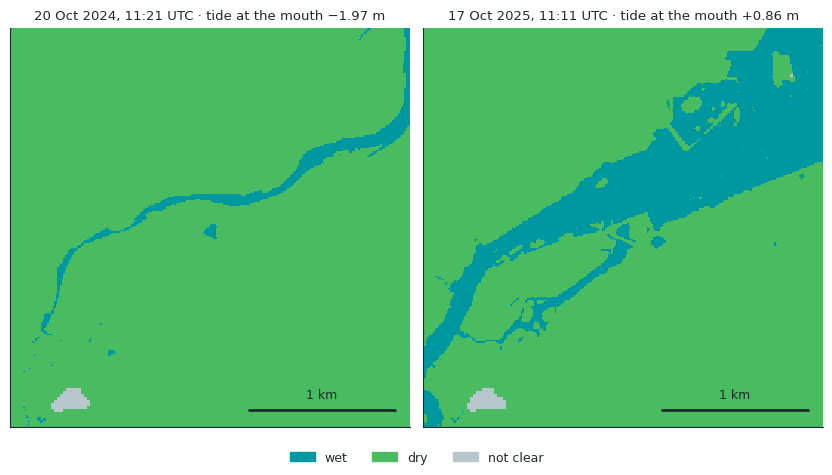

In [4]:
# two scenes, chosen by a rule: among the 30 clearest scenes of the block, the one at the lowest tide
# and the one at the highest tide
share = clear.mean(axis=(1, 2))                             # the share of clear looks of each scene
top = np.argsort(share)[-30:]
pick = [top[np.argmin(h0[top])], top[np.argmax(h0[top])]]
looks = ListedColormap([RULE, DRY, WET])                    # 0 not clear, 1 dry, 2 wet
fig, axs = plt.subplots(1, 2, figsize=(8.4, 4.6))
for ax, i in zip(axs, pick):
    ax.imshow(np.where(clear[i], 1 + wet[i], 0), cmap=looks, vmin=0, vmax=2)
    ax.set_title(f'{dates[i]:%d %b %Y}, {dates[i]:%H:%M} UTC · tide at the mouth {metres(h0[i])}')
    ax.set_xticks([])
    ax.set_yticks([])
    scale_bar(ax, H, W, right=True)
handles = [Patch(color=WET, label='wet'), Patch(color=DRY, label='dry'), Patch(color=RULE, label='not clear')]
fig.legend(handles=handles, loc='lower center', ncol=3)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## 2 · One pixel

MAREA fits each pixel's looks with its flooding curve: NDWI = a + b · Φ((h − z) / σ), where h is the water level at the overpass and Φ the normal curve, an assumed S shape (`guide/METHOD.md`, section 2). The curve's midpoint z is the pixel's **elevation**; its width σ is shown as the **uncertainty** of z (it is not a standard error).

Inside the ría the tide arrives late. A pixel whose water is τ minutes late sees, at the overpass, the level the mouth had τ minutes earlier, so MAREA fits it against that delayed tide. The pixel below is chosen by a rule written before looking at it: among the pixels with the largest delay in the block, the one whose elevation is closest to the median elevation of those pixels.

In [5]:
inter = s['intertidal'].values == 1                         # MAREA's pixels in the block
z_st = s['z_marea'].values                                  # the product's elevation, m
sg_st = s['sigma_marea'].values                             # the product's width of the step, m
tau_st = s['delay_marea'].values                            # the delay the product gave each pixel, min
lo, hi = float(h0.min()), float(h0.max())                   # MAREA searches elevations inside the record's range

# the rule: the largest delay of the block, then the elevation closest to those pixels' median
# (on a tie, the first pixel in row-major order)
tau_max = np.nanmax(tau_st[inter])
cand = inter & (tau_st == tau_max) & np.isfinite(z_st)
r, c = np.argwhere(cand)[np.argmin(np.abs(z_st[cand] - np.median(z_st[cand])))]
tau = int(tau_st[r, c])
y = np.nan_to_num(ndwi[:, r, c], nan=0.0).astype(float)     # the pixel's NDWI series (no value as 0, as MAREA)
ok = clear[:, r, c]                                         # its clear looks
h_late = s['tide_level_delayed'].sel(delay=tau).values      # the mouth's level tau minutes before each overpass

# MAREA's inversion of this one pixel, against each tide
Y1, C1 = y[:, None], ok[:, None].astype(float)
z_mouth, sg_mouth = (v[0] for v in marea.invert_series(Y1, C1, h0, lo, hi))
z_late, sg_late = (v[0] for v in marea.invert_series(Y1, C1, h_late, lo, hi))
assert np.float32(z_late) == z_st[r, c] and np.float32(sg_late) == sg_st[r, c]   # the product's values, exactly
x_m, y_m, s_m = float(s['x'][c]), float(s['y'][r]), float(s['s_km'][r, c])
print(f'pixel row {r}, column {c} of the block (UTM 30N x {x_m:.0f} m, y {y_m:.0f} m), {s_m:.2f} km from the '
      f'mouth along the water: delay {tau} min, {ok.sum()} clear looks of {T}')
print(f'  against the tide at the mouth:       z = {z_mouth:+.3f} m, sigma = {sg_mouth:.2f} m')
print(f'  against its own tide, {tau} min late: z = {z_late:+.3f} m, sigma = {sg_late:.2f} m (the product)')
print(f'the delay moves this pixel by {z_late - z_mouth:+.3f} m')

pixel row 140, column 124 of the block (UTM 30N x 305165 m, y 4820135 m), 8.36 km from the mouth along the water: delay 15 min, 94 clear looks of 97
  against the tide at the mouth:       z = +0.537 m, sigma = 0.03 m
  against its own tide, 15 min late: z = +0.469 m, sigma = 0.22 m (the product)
the delay moves this pixel by -0.068 m


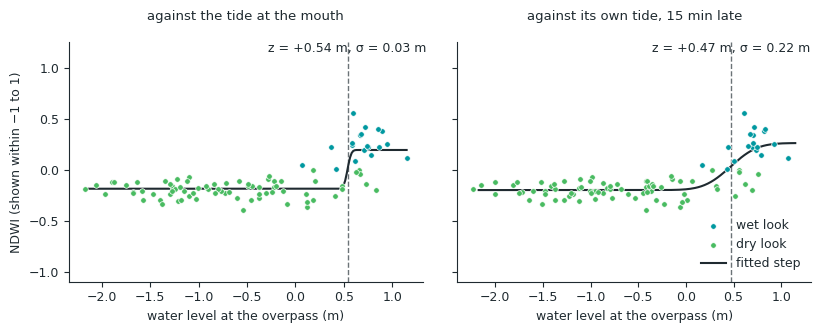

In [6]:
def step(h, y, ok, z, sg):
    # the step's (a, b) for a given z and sigma: least squares on the clear looks
    phi = 0.5 * (1 + erf((h[ok] - z) / (sg * np.sqrt(2))))
    (a, b), *_ = np.linalg.lstsq(np.c_[np.ones(ok.sum()), phi], y[ok], rcond=None)
    return a, b


hh = np.linspace(lo, hi, 200)                               # the curve, over the searched range
fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.4), sharey=True)
for ax, h, z, sg, title in ((axs[0], h0, z_mouth, sg_mouth, 'against the tide at the mouth'),
                            (axs[1], h_late, z_late, sg_late, f'against its own tide, {tau} min late')):
    for mask, colour, label in ((ok & (y > 0), WET, 'wet look'), (ok & (y <= 0), DRY, 'dry look')):
        ax.scatter(h[mask], np.clip(y[mask], -1, 1), s=16, color=colour, edgecolor='white', linewidth=0.5,
                   label=label, zorder=3)
    if np.isfinite(z):
        a, b = step(h, y, ok, z, sg)
        ax.plot(hh, a + b * 0.5 * (1 + erf((hh - z) / (sg * np.sqrt(2)))), color=INK, lw=1.5, zorder=2,
                label='fitted step')
        ax.axvline(z, color=GREY, lw=1, ls='--', zorder=1)
        ax.text(z, 1.12, f'z = {metres(z)}, σ = {sg:.2f} m', ha='center', va='bottom', color=INK)
    ax.set_title(title, pad=16)
    ax.set_xlabel('water level at the overpass (m)')
axs[0].set_ylabel('NDWI (shown within −1 to 1)')
axs[0].set_ylim(-1.1, 1.25)
axs[1].legend(loc='lower right')
fig.tight_layout()
plt.show()

A pixel's delay is not fitted from its own looks: it comes from all the pixels of its 3-km section (section 4), smoothed along the distance from the mouth. The smoothing pulls the delays of the inner reach below their section's fit: this pixel, in the last section, receives 15 min, while that section's delay is 20.7 min (`guide/METHOD.md`, section 5).

Its width σ grows from 0.03 m against the mouth tide to 0.22 m against its own tide. The delay is not chosen to suit this pixel: it is fitted on all the pixels of the section and then smoothed, so it need not be the shift under which this pixel's own wet and dry looks line up most sharply. σ absorbs such errors in the timing of each look, as well as the relief inside the pixel (`guide/METHOD.md`, section 8).

## 3 · The whole block

Every MAREA pixel of the block, inverted with the delay the product gave it, returns the product's elevation and width exactly. The inversion runs once per delay, as `marea.reconstruct` runs it, with no quality rule (the product predates it).

In [7]:
rows, cols = np.nonzero(inter)                              # MAREA's pixels of the block, row-major
Y = np.nan_to_num(ndwi[:, rows, cols], nan=0.0).astype(np.float64)   # (scene, pixel), no value as 0
C = clear[:, rows, cols].astype(np.float64)
tau_px = tau_st[rows, cols]
z = np.full(len(rows), np.nan)
sg = np.full(len(rows), np.nan)
for d in np.unique(tau_px):                                 # the pixels that share a delay, together
    j = np.flatnonzero(tau_px == d)
    h = s['tide_level_delayed'].sel(delay=int(d)).values    # the mouth's level d minutes before each overpass
    z[j], sg[j] = marea.invert_series(Y[:, j], C[:, j], h, lo, hi)


def identical(a, b):
    # the pixels where both are NaN or both hold the same float32
    a, b = np.asarray(a, np.float32), np.asarray(b, np.float32)
    return int(((np.isnan(a) & np.isnan(b)) | (a == b)).sum())


n_px, n_z, n_sg = len(rows), identical(z, z_st[rows, cols]), identical(sg, sg_st[rows, cols])
n_val = int(np.isfinite(z).sum())
print(f'{n_px:,} MAREA pixels in the block, delays {tau_px.min():.0f} to {tau_px.max():.0f} min; '
      f'{n_val:,} hold an elevation')
print(f'elevation identical to the product on {n_z:,} of {n_px:,} pixels; width on {n_sg:,} of {n_px:,}')
assert n_z == n_sg == n_px == 15064
s.close()
del ndwi, clear, wet, Y, C                                  # free the block before the whole ría

15,064 MAREA pixels in the block, delays 0 to 15 min; 14,171 hold an elevation
elevation identical to the product on 15,064 of 15,064 pixels; width on 15,064 of 15,064


## 4 · The whole ría, from the replication kit

The kit holds the record of every intertidal pixel of the ría (97 scenes × 32,120 pixels) and EOT20 at the record's instants, shifted by every whole minute from −45 to 180. From them, `marea.reconstruct` finds the mouth, the distance along the water and the 3-km sections; fits one delay per section, with a 95 % interval from 30 scene resamples; gives every pixel its delay from a smooth curve through the section delays; and fits every pixel's elevation. The run writes to a temporary folder and is checked against `products_marea/` with 41 checks.

In [8]:
cfg = mt.load_site('scripts/sites/villaviciosa.yaml')       # the product's settings, unchanged
m = cfg['marea']
kit = Path('replication')
record = kit / 'villaviciosa_record_2023-2025.npz'
ex = mt.load_extraction(record)                             # the looks of every intertidal pixel of the ría
times = mt.load_overpass(cfg['overpass_times'])             # the acquisition time of every scene, UTC
tide = mt.TableBoundary(kit / 'villaviciosa_eot20_levels.npz')   # EOT20 at the mouth, tabulated: no model needed
n_sc, n_pix = ex['Y'].shape
print(f'record: {n_sc} scenes x {n_pix:,} intertidal pixels; tide: {tide.name} at ({tide.lat:.5f}, {tide.lon:.5f})')

run = tempfile.TemporaryDirectory()                         # the run's own files, deleted after section 5
t0 = time.time()
res = marea.reconstruct(
    str(record), run.name, name='Villaviciosa', boundary=tide, extraction=ex, overpass_times=times,
    mouth_side=m['mouth_side'], band_km=float(m['band_km']), min_px_band=int(m['min_px_band']),
    n_boot=int(m['n_boot']), min_scenes=int(m['min_scenes']),
    quality_min_bracket=int(m['quality_min_bracket']), verbose=False)
seconds = time.time() - t0

s_max, n_sec, n_boot = res['s_max_km'], len(res['centros_km']), res['n_boot']
print(f'the mouth found; the water reaches {s_max:.2f} km inland; {n_sec} sections of 3 km '
      f'({seconds:.0f} s, {n_boot} scene resamples)')
for k, (centre, d, d_lo, d_hi) in enumerate(zip(res['centros_km'], res['tau_usado_min'],
                                                res['tau_lo_min'], res['tau_hi_min'])):
    note = '  (the mouth: pinned at 0)' if k == 0 else ''
    print(f'  section {k}: centre {centre:.2f} km · delay {d:5.2f} min · 95 % interval {d_lo:.1f} to {d_hi:.1f} min{note}')
med, mx, n_cota, n_all = res['tau_px_median_min'], res['tau_px_max_min'], res['n_px_cota'], res['n_px']
print(f'per-pixel delay: median {med:.0f} min, largest {mx:.0f} min; {n_cota:,} of {n_all:,} pixels hold an elevation')

record: 97 scenes x 32,120 intertidal pixels; tide: EOT20 at (43.50902, -5.41613)


the mouth found; the water reaches 9.15 km inland; 3 sections of 3 km (33 s, 30 scene resamples)
  section 0: centre 1.49 km · delay  0.00 min · 95 % interval 0.0 to 0.0 min  (the mouth: pinned at 0)
  section 1: centre 4.27 km · delay  5.05 min · 95 % interval 0.0 to 17.9 min
  section 2: centre 7.57 km · delay 20.74 min · 95 % interval 13.1 to 28.7 min
per-pixel delay: median 6 min, largest 16 min; 29,728 of 32,120 pixels hold an elevation


In [9]:
# the checks: every array of marea.npz and every key of result.json against products_marea/
expected_sha = manifest['files'][record.name]['sha256']     # reconstruct records the sha256 of its input
checks, passed = mt.compare_products(run.name, 'products_marea', expected_cube_sha=expected_sha)
print(mt.format_table(checks, ('check', 'expected', 'found', 'tolerance', 'status')))
n_pass = sum(row[4] == 'PASS' for row in checks)
print(f'\n{n_pass} of {len(checks)} checks passed: the product, reproduced')
assert passed and n_pass == len(checks) == 41

check                            expected                                          found                                             tolerance  status
-------------------------------  ------------------------------------------------  ------------------------------------------------  ---------  ------
marea.npz keep                   int64(32120,)                                     identical                                         identical  PASS
marea.npz shape                  int64(2,)                                         identical                                         identical  PASS
marea.npz z                      float32(32120,)                                   identical                                         identical  PASS
marea.npz sigma                  float32(32120,)                                   identical                                         identical  PASS
marea.npz s_km                   float32(32120,)                                   identical          

## 5 · The maps

The reproduced product as maps: the elevation z, its uncertainty σ, the delay τ each pixel received and the **emersion time**, the share of 2023–2025 each pixel spends out of the water under its own delayed tide (EOT20 every 10 minutes, from the kit). Land is grey and water light grey; intertidal pixels without a value are left as water.

emersion time: median 53 % of the time (10th to 90th percentile 18 to 68 %)


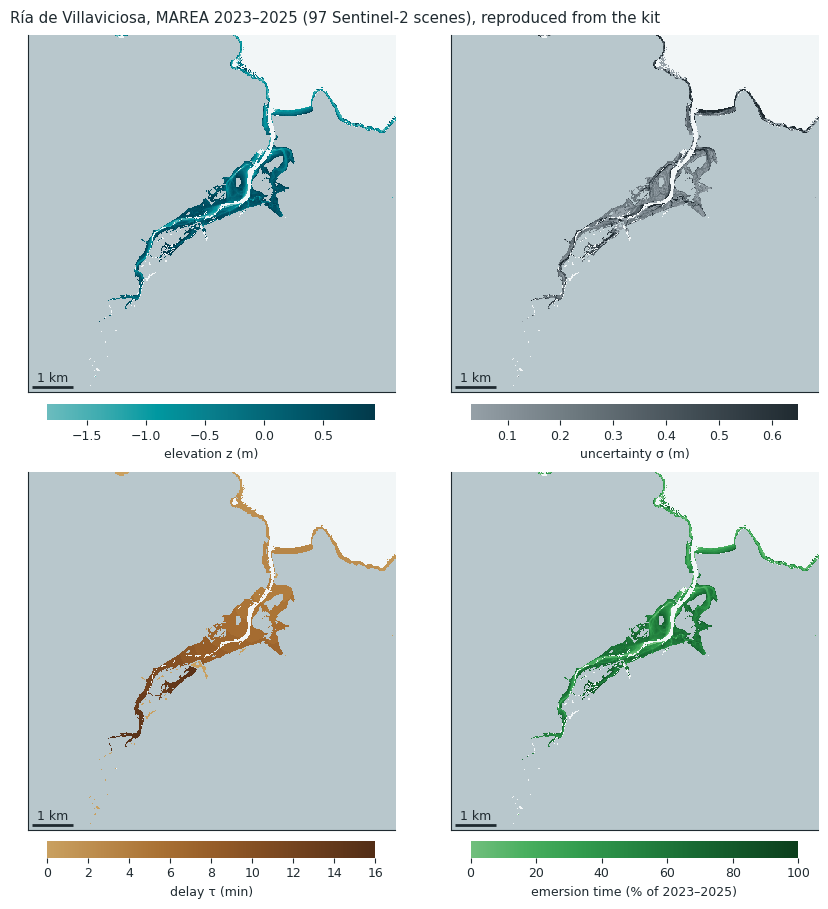

In [10]:
with np.load(Path(run.name) / 'marea.npz') as d:
    prod = {k: d[k] for k in ('z', 'sigma', 'tau_px_min', 'keep', 'shape')}
emersion = mt.emersion_time(prod['z'], prod['tau_px_min'], kit / 'villaviciosa_eot20_10min_2023-2025.npz',
                            '2023-01-01', '2026-01-01', step_min=10)   # share of time out of the water, 0-1
run.cleanup()                                               # the run's files are no longer needed
q = np.nanpercentile(100 * emersion, [10, 50, 90])
print(f'emersion time: median {q[1]:.0f} % of the time (10th to 90th percentile {q[0]:.0f} to {q[2]:.0f} %)')

FH, FW = (int(v) for v in prod['shape'])                    # the 915 x 915 frame of 10 m pixels


def frame(values):
    # a per-pixel array as an image of the frame (NaN outside MAREA's pixels)
    img = np.full(FH * FW, np.nan, np.float32)
    img[prod['keep']] = values
    return img.reshape(FH, FW)


inside = ~np.isnan(frame(np.zeros(len(prod['keep']))))      # MAREA's pixels
base = ex['sea'] | inside                                   # water, or intertidal: drawn as water
rr, cc = np.nonzero(inside)                                 # the maps show the intertidal area and a margin
r0, r1 = max(rr.min() - 15, 0), min(rr.max() + 16, FH)
c0, c1 = max(cc.min() - 15, 0), min(cc.max() + 16, FW)
layers = [(frame(prod['z']), 'z', 'elevation z (m)', np.nanpercentile(prod['z'], [2, 98])),
          (frame(prod['sigma']), 'sigma', 'uncertainty σ (m)', (0.03, 0.65)),
          (frame(prod['tau_px_min']), 'tau', 'delay τ (min)', (0, 16)),
          (frame(100 * emersion), 'emersion', 'emersion time (% of 2023–2025)', (0, 100))]
fig, axs = plt.subplots(2, 2, figsize=(8.6, 9.2))
for ax, (img, name, label, (vmin, vmax)) in zip(axs.ravel(), layers):
    ax.imshow(base[r0:r1, c0:c1], cmap=ListedColormap([RULE, TINT]), vmin=0, vmax=1)
    im = ax.imshow(img[r0:r1, c0:c1], cmap=ramp(name), vmin=vmin, vmax=vmax)
    ax.set_xticks([])
    ax.set_yticks([])
    scale_bar(ax, r1 - r0, c1 - c0)
    bar = fig.colorbar(im, ax=ax, orientation='horizontal', fraction=0.05, pad=0.03, shrink=0.8)
    bar.set_label(label)
    bar.outline.set_visible(False)
fig.suptitle('Ría de Villaviciosa, MAREA 2023–2025 (97 Sentinel-2 scenes), reproduced from the kit', x=0.02, ha='left')
fig.tight_layout()
plt.show()

## What next

* `notebooks/02_tide_per_image.ipynb`: the tide at each of the 97 images, flood or ebb, the level each section sees, and how much of the tide range the images cover.
* `notebooks/03_new_ria_openeo.ipynb`: a new ría with openEO, as a dry run with its credit estimate.
* `guide/NEW_ESTUARY.md`: an estuary of your own: the rules for drawing the box, the chain of calls and how to judge a run.
* `python scripts/reproduce_villaviciosa.py --from-kit replication` runs section 4 from the command line.
* The map viewer shows these layers for four estuaries of northern Spain (Foz, Eo, Villaviciosa and Mundaka), with heights in m above NMMA: https://coastal-ai.github.io/Intertidal_analysis/

Data: contains modified Copernicus Sentinel data 2023–2025. Water levels: EOT20 (Hart-Davis et al. 2021, SEANOE, https://doi.org/10.17882/79489), CC BY 4.0.